<a href="https://colab.research.google.com/github/KeshavKSV/Advanced-Image-Classifier-with-Out-of-Distribution-Detection-/blob/main/OOD_DETECTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Download the AWA2 dataset
!wget https://cvml.ist.ac.at/AwA2/AwA2-data.zip

# Unzip the dataset into the correct folder
!unzip -q AwA2-data.zip -d /content/AWA2/

# Delete the zip file to save disk space
!rm AwA2-data.zip

# Verify the files are there
!ls /content/AWA2/JPEGImages/

--2026-08-26 22:51:21--  https://cvml.ist.ac.at/AwA2/AwA2-data.zip
Resolving cvml.ist.ac.at (cvml.ist.ac.at)... 78.104.209.17
Connecting to cvml.ist.ac.at (cvml.ist.ac.at)|78.104.209.17|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://cvml.ista.ac.at/AwA2/AwA2-data.zip [following]
--2026-08-26 22:51:22--  https://cvml.ista.ac.at/AwA2/AwA2-data.zip
Resolving cvml.ista.ac.at (cvml.ista.ac.at)... 78.104.209.17
Connecting to cvml.ista.ac.at (cvml.ista.ac.at)|78.104.209.17|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13923888724 (13G) [application/zip]
Saving to: ‘AwA2-data.zip’

AwA2-data.zip       100%[===================>]  12.97G  32.6MB/s    in 8m 2s   

2026-08-26 22:59:24 (27.6 MB/s) - ‘AwA2-data.zip’ saved [13923888724/13923888724]

ls: cannot access '/content/AWA2/JPEGImages/': No such file or directory


In [ ]:
# Verify the files are there
!ls /content/AWA2/Animals_with_Attributes2/JPEGImages/

antelope    cow		     gorilla	     mole	  raccoon	 tiger
bat	    dalmatian	     grizzly+bear    moose	  rat		 walrus
beaver	    deer	     hamster	     mouse	  rhinoceros	 weasel
blue+whale  dolphin	     hippopotamus    otter	  seal		 wolf
bobcat	    elephant	     horse	     ox		  sheep		 zebra
buffalo     fox		     humpback+whale  persian+cat  siamese+cat
chihuahua   german+shepherd  killer+whale    pig	  skunk
chimpanzee  giant+panda      leopard	     polar+bear   spider+monkey
collie	    giraffe	     lion	     rabbit	  squirrel


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder, SVHN
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import roc_auc_score
import numpy as np
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 1. Define standard ResNet transforms (resize to 224x224 and normalize)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Load In-Distribution Data (AWA2)
print("Loading ID Data (AWA2)...")
AWA2_PATH = "/content/AWA2/Animals_with_Attributes2/JPEGImages"

if not os.path.exists(AWA2_PATH):
    print(f"Error: Could not find AWA2 at {AWA2_PATH}. Make sure you unzipped it!")
else:
    awa2_data = ImageFolder(root=AWA2_PATH, transform=transform)

    # Use 80% of the FULL dataset so the Mahalanobis math works perfectly
    train_size = int(0.8 * len(awa2_data))
    test_size = len(awa2_data) - train_size
    awa2_train, awa2_test = random_split(awa2_data, [train_size, test_size])

    id_train_loader = DataLoader(awa2_train, batch_size=64, shuffle=True)
    id_test_loader = DataLoader(awa2_test, batch_size=64, shuffle=False)
    num_classes = len(awa2_data.classes)
    print(f"AWA2 Loaded successfully! Training on {train_size} images.")

# 3. Load Out-of-Distribution Data (SVHN instead of CIFAR-10)
print("Downloading/Loading OOD Data (SVHN from Stanford servers)...")
ood_data = SVHN(root="/content/data", split='test', download=True, transform=transform)
ood_test_loader = DataLoader(ood_data, batch_size=64, shuffle=False)

print("Data loaded! You can now move to Cell 2.")

Using device: cpu
Loading ID Data (AWA2)...
AWA2 Loaded successfully! Training on 29857 images.
Downloading/Loading OOD Data (SVHN from Stanford servers)...


100%|██████████| 64.3M/64.3M [00:27<00:00, 2.37MB/s]


Data loaded! You can now move to Cell 2.


In [ ]:
from tqdm import tqdm # This library creates the loading bar

class DualOutputResNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        # Isolate features (everything before the final layer)
        self.features = nn.Sequential(*list(resnet.children())[:-1])
        # Replace final layer for CIFAR-100 classes
        self.classifier = nn.Linear(resnet.fc.in_features, num_classes)

    def forward(self, x):
        feat = self.features(x)
        feat = torch.flatten(feat, 1)
        logits = self.classifier(feat)
        return logits, feat

model = DualOutputResNet(num_classes).to(device)

# Quick 1-Epoch Fine-Tuning so the classifier learns the CIFAR-100 classes
print("Training model on CIFAR-100... (This will take a few minutes)")
model.train()
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# We wrap id_train_loader with tqdm() to see exactly how fast it is processing
for images, labels in tqdm(id_train_loader, desc="Training Progress"):
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    logits, _ = model(images)
    loss = criterion(logits, labels)
    loss.backward()
    optimizer.step()

print("\nTraining complete.")

Training model on CIFAR-100... (This will take a few minutes)


Training Progress: 100%|██████████| 467/467 [1:34:27<00:00, 12.14s/it]


Training complete.


In [ ]:
from tqdm import tqdm

model.eval()
print("Extracting training features to build Mahalanobis clusters...")

all_features = []
all_labels = []

# 1. Extract features for the entire training set
with torch.no_grad():
    for images, labels in tqdm(id_train_loader, desc="Extracting Features"):
        _, features = model(images.to(device))
        all_features.append(features.cpu())
        all_labels.append(labels)

all_features = torch.cat(all_features)
all_labels = torch.cat(all_labels)

# 2. Compute Class Means
feature_dim = all_features.shape[1]
class_means = torch.zeros((num_classes, feature_dim))
for c in range(num_classes):
    class_features = all_features[all_labels == c]
    if len(class_features) > 0:
        class_means[c] = class_features.mean(dim=0)

# 3. Compute Tied Covariance Matrix and its Inverse
print("Calculating Covariance Matrix (this will take a minute)...")
covariance = torch.zeros((feature_dim, feature_dim))

# Adding a progress bar here too since it iterates 30,000 times
for i in tqdm(range(len(all_features)), desc="Building Matrix"):
    x = all_features[i].unsqueeze(1)
    mu = class_means[all_labels[i]].unsqueeze(1)
    diff = x - mu
    covariance += torch.mm(diff, diff.t())

covariance /= len(all_features)

# --- THE FIX: COVARIANCE REGULARIZATION ---
# Add a small smoothing factor (epsilon) to the diagonal to stabilize the matrix
epsilon = 0.01
identity_matrix = torch.eye(feature_dim)
smoothed_covariance = covariance + (epsilon * identity_matrix)

# Now we can safely use the standard inverse
inverse_covariance = torch.linalg.inv(smoothed_covariance).to(device)
class_means = class_means.to(device)

print("\nMahalanobis setup complete. You can now run Cell 4.")

Extracting training features to build Mahalanobis clusters...


Extracting Features: 100%|██████████| 467/467 [38:35<00:00,  4.96s/it]


Calculating Covariance Matrix (this will take a minute)...


Building Matrix: 100%|██████████| 29857/29857 [00:02<00:00, 11268.01it/s]



Mahalanobis setup complete. You can now run Cell 4.


In [ ]:
from tqdm import tqdm
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

def evaluate_ood_methods(dataloader, desc="Evaluating"):
    softmax_scores = []
    mahalanobis_scores = []

    with torch.no_grad():
        # Added tqdm here to show a loading bar for the evaluation!
        for images, _ in tqdm(dataloader, desc=desc):
            images = images.to(device)
            logits, features = model(images)

            # --- METHOD 1: Standard Softmax (NN Baseline) ---
            # Confidence is the maximum probability across all classes
            probs = F.softmax(logits, dim=1)
            max_probs, _ = torch.max(probs, dim=1)
            softmax_scores.extend(max_probs.cpu().numpy())

            # --- METHOD 2: Mahalanobis Distance ---
            # Calculate distance from each sample to every class mean
            batch_md_scores = []
            for c in range(num_classes):
                delta = features - class_means[c]
                left = torch.matmul(delta, inverse_covariance)
                dist = torch.sum(left * delta, dim=1)
                batch_md_scores.append(-dist) # Negative distance = Confidence

            batch_md_scores = torch.stack(batch_md_scores, dim=1)
            max_md_scores, _ = torch.max(batch_md_scores, dim=1)
            mahalanobis_scores.extend(max_md_scores.cpu().numpy())

    return np.array(softmax_scores), np.array(mahalanobis_scores)

print("Evaluating ID data (AWA2)...")
id_soft, id_mah = evaluate_ood_methods(id_test_loader, desc="AWA2 (Normal)")

print("\nEvaluating OOD data (SVHN)...")
ood_soft, ood_mah = evaluate_ood_methods(ood_test_loader, desc="SVHN (Anomaly)")

# Create ground-truth labels: 1 for ID (Normal), 0 for OOD (Anomaly)
y_true = np.concatenate([np.ones(len(id_soft)), np.zeros(len(ood_soft))])

# Concatenate predictions
y_scores_softmax = np.concatenate([id_soft, ood_soft])
y_scores_mahalanobis = np.concatenate([id_mah, ood_mah])

# Calculate AUROC
auroc_softmax = roc_auc_score(y_true, y_scores_softmax)
auroc_mahalanobis = roc_auc_score(y_true, y_scores_mahalanobis)

print("\n--- OOD DETECTION ACCURACY (AUROC) ---")
print(f"Standard NN (Softmax): {auroc_softmax * 100:.2f}%")
print(f"Feature-Space (Mahalanobis): {auroc_mahalanobis * 100:.2f}%")

Evaluating ID data (AWA2)...


AWA2 (Normal): 100%|██████████| 117/117 [08:44<00:00,  4.48s/it]



Evaluating OOD data (SVHN)...


SVHN (Anomaly): 100%|██████████| 407/407 [24:00<00:00,  3.54s/it]


--- OOD DETECTION ACCURACY (AUROC) ---
Standard NN (Softmax): 99.78%
Feature-Space (Mahalanobis): 92.28%


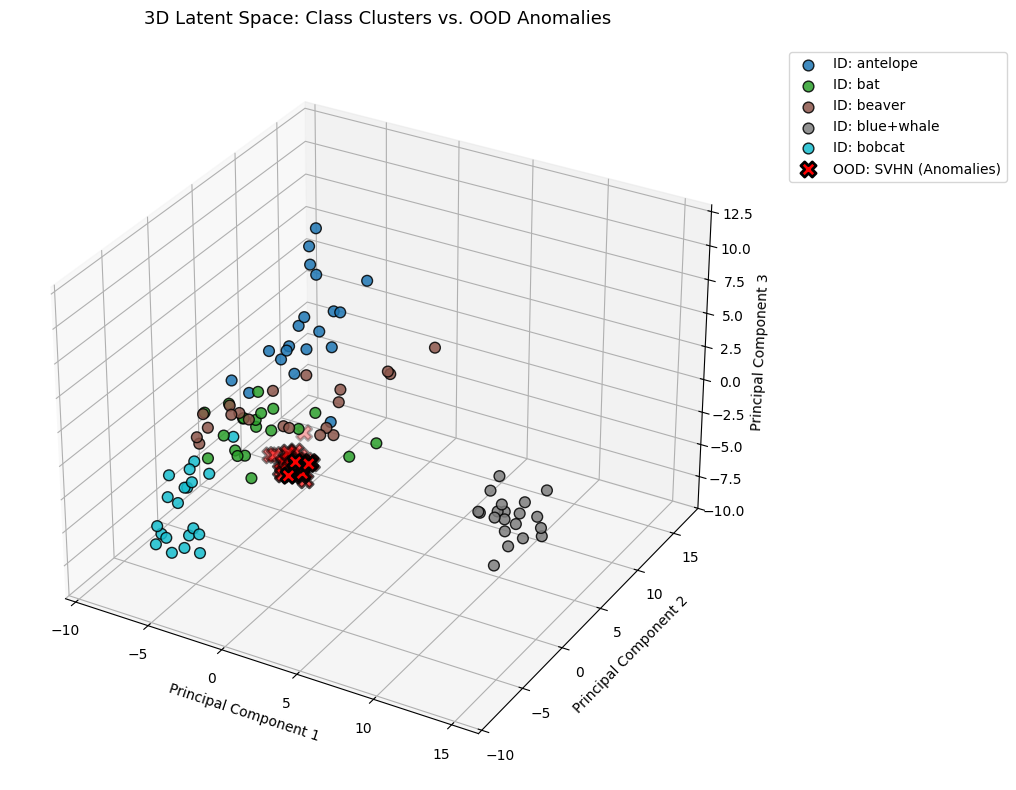


--- DISTANCE SUMMARY ---
Average In-Distribution Distance:     475.54
Average Out-of-Distribution Distance: 801.67
Separation Multiplier: OOD is 1.7x further from class centroids.


In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import numpy as np
import torch

# 1. Configuration: pick how many classes and samples to show
NUM_CLASSES_TO_PLOT = 5    # Top 5 animal classes
SAMPLES_PER_CLASS = 20     # 20 samples per animal class
OOD_SAMPLES = 25           # 25 anomaly samples

print("Collecting balanced samples from each class...")

# Extract samples per class from the ID dataset
class_samples = {c: [] for c in range(NUM_CLASSES_TO_PLOT)}
model.eval()

with torch.no_grad():
    for imgs, lbls in id_train_loader:
        _, feats = model(imgs.to(device))
        feats = feats.cpu()

        for feat, lbl in zip(feats, lbls):
            c = lbl.item()
            if c < NUM_CLASSES_TO_PLOT and len(class_samples[c]) < SAMPLES_PER_CLASS:
                class_samples[c].append(feat.numpy())

        # Stop once we have 20 samples for all chosen classes
        if all(len(samples) >= SAMPLES_PER_CLASS for samples in class_samples.values()):
            break

# Extract OOD samples
ood_samples_list = []
with torch.no_grad():
    for imgs, _ in ood_test_loader:
        _, feats = model(imgs.to(device))
        ood_samples_list.extend(feats.cpu().numpy())
        if len(ood_samples_list) >= OOD_SAMPLES:
            break
ood_samples_list = np.array(ood_samples_list[:OOD_SAMPLES])

# 2. Combine and project using PCA
all_id_feats = np.vstack([np.array(class_samples[c]) for c in range(NUM_CLASSES_TO_PLOT)])
pca = PCA(n_components=3)
pca.fit(all_id_feats)

# 3. Create the 3D Plot
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

# Distinct color palette for each animal class
colors = plt.cm.tab10(np.linspace(0, 1, NUM_CLASSES_TO_PLOT))

# Plot each ID Animal Class in its own unique color
for c in range(NUM_CLASSES_TO_PLOT):
    feats_3d = pca.transform(np.array(class_samples[c]))
    class_name = awa2_data.classes[c] if 'awa2_data' in globals() else f"Class {c}"
    ax.scatter(
        feats_3d[:, 0], feats_3d[:, 1], feats_3d[:, 2],
        color=colors[c], s=60, alpha=0.85, edgecolors='k',
        label=f"ID: {class_name}"
    )

# Plot OOD Anomaly Samples (Bright Red / Black 'X')
ood_3d = pca.transform(ood_samples_list)
ax.scatter(
    ood_3d[:, 0], ood_3d[:, 1], ood_3d[:, 2],
    c='red', marker='X', s=120, linewidths=2, edgecolors='black',
    label='OOD: SVHN (Anomalies)', zorder=10
)

ax.set_title("3D Latent Space: Class Clusters vs. OOD Anomalies", fontsize=13, pad=15)
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 4. Quantitative Summary
avg_id_distance = -np.mean(id_mah)
avg_ood_distance = -np.mean(ood_mah)
print("\n--- DISTANCE SUMMARY ---")
print(f"Average In-Distribution Distance:     {avg_id_distance:.2f}")
print(f"Average Out-of-Distribution Distance: {avg_ood_distance:.2f}")
print(f"Separation Multiplier: OOD is {avg_ood_distance / avg_id_distance:.1f}x further from class centroids.")

Extracting features for 3D visualization...


SVHN OOD: 100%|██████████| 407/407 [01:07<00:00,  6.00it/s]



Subsampling data for stable 3D plotting...


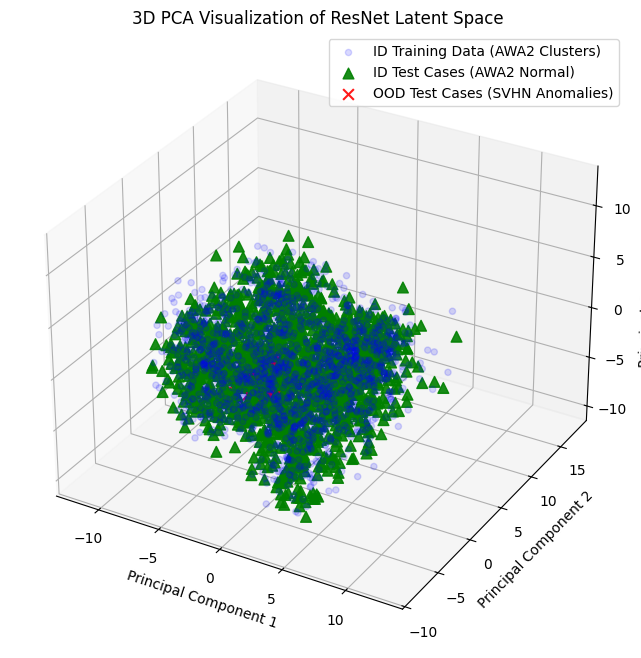


--- QUANTITATIVE DISTANCE PARAMETERS ---
Average Mahalanobis Distance for ID Test Cases (Normal):  476.24
Average Mahalanobis Distance for OOD Test Cases (Anomaly): 802.61
Distance Multiplier: Anomalies are on average 1.7x further away from the safety clusters than normal data.


In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import numpy as np
import torch
from tqdm import tqdm

# 1. Extract raw features for all datasets
def get_features(dataloader, desc):
    features_list = []
    labels_list = []
    model.eval()
    with torch.no_grad():
        for imgs, lbls in tqdm(dataloader, desc=desc):
            _, feats = model(imgs.to(device))
            features_list.append(feats.cpu())
            labels_list.append(lbls)
    return torch.cat(features_list).numpy(), torch.cat(labels_list).numpy()

print("Extracting features for 3D visualization...")
train_feats, train_lbls = get_features(id_train_loader, desc="AWA2 Train")
id_test_feats, id_test_lbls = get_features(id_test_loader, desc="AWA2 Test")
ood_feats, _ = get_features(ood_test_loader, desc="SVHN OOD")

# --- CRITICAL FIX: SUBSAMPLING FOR VISUALIZATION ---
# Plotting 60,000+ points will crash the browser. We limit it to 1,500 points each.
print("\nSubsampling data for stable 3D plotting...")
plot_limit = 1500
train_feats_plot = train_feats[:plot_limit]
id_test_feats_plot = id_test_feats[:plot_limit]
ood_feats_plot = ood_feats[:plot_limit]

# 2. Apply PCA to map 512-D features down to 3-D
# We fit the PCA ONLY on the training data to define our "normal" space
pca = PCA(n_components=3)
pca.fit(train_feats_plot)

train_3d = pca.transform(train_feats_plot)
id_test_3d = pca.transform(id_test_feats_plot)
ood_3d = pca.transform(ood_feats_plot)

# 3. Create the 3D Plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot ID Training Clusters (Faint Blue Dots)
ax.scatter(train_3d[:, 0], train_3d[:, 1], train_3d[:, 2],
           c='blue', alpha=0.15, label='ID Training Data (AWA2 Clusters)')

# Plot ID Test Cases (Green Triangles) - Should overlap with blue
ax.scatter(id_test_3d[:, 0], id_test_3d[:, 1], id_test_3d[:, 2],
           c='green', alpha=0.9, marker='^', s=60, label='ID Test Cases (AWA2 Normal)')

# Plot OOD Test Cases (Red X's) - Should be far away
ax.scatter(ood_3d[:, 0], ood_3d[:, 1], ood_3d[:, 2],
           c='red', alpha=0.9, marker='x', s=60, label='OOD Test Cases (SVHN Anomalies)')

ax.set_title("3D PCA Visualization of ResNet Latent Space")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")
ax.legend()
plt.show()

# 4. Print the Quantitative Parameters (Distances)
avg_id_distance = -np.mean(id_mah)
avg_ood_distance = -np.mean(ood_mah)

print("\n--- QUANTITATIVE DISTANCE PARAMETERS ---")
print(f"Average Mahalanobis Distance for ID Test Cases (Normal):  {avg_id_distance:.2f}")
print(f"Average Mahalanobis Distance for OOD Test Cases (Anomaly): {avg_ood_distance:.2f}")
print(f"Distance Multiplier: Anomalies are on average {avg_ood_distance / avg_id_distance:.1f}x further away from the safety clusters than normal data.")

In [ ]:
import torch
import numpy as np
import torch.nn as nn

print("--- 1. Setting up Forward Hooks ---")
# 1. Define the missing dictionary and hook function
intermediate_features = {}

def get_features(name):
    def hook(model, input, output):
        pooled = torch.mean(output, dim=[2, 3])
        intermediate_features[name] = pooled
    return hook

# 2. Attach hooks to the ResNet-18 layers
# Access layer1, layer2, layer3, layer4 through model.features (which is an nn.Sequential)
# Based on the structure of ResNet18, these are at indices 4, 5, 6, 7 of the features sequence.
model.features[4].register_forward_hook(get_features('layer1'))
model.features[5].register_forward_hook(get_features('layer2'))
model.features[6].register_forward_hook(get_features('layer3'))
model.features[7].register_forward_hook(get_features('layer4'))

print("--- 2. Calibrating Multi-Layer Mahalanobis Parameters ---")
layer_names = ['layer1', 'layer2', 'layer3', 'layer4']
num_classes = 50
epsilon = 0.01

layer_class_means = {layer: {} for layer in layer_names}
layer_inverse_covariances = {}
layer_features_by_class = {layer: {c: [] for c in range(num_classes)} for layer in layer_names}

model.eval()
with torch.no_grad():
    print("Extracting features across all layers...")
    for imgs, labels in id_train_loader:
        imgs = imgs.to(device)

        # Forward pass triggers the hooks and populates 'intermediate_features'
        _ = model(imgs)

        for i, label in enumerate(labels):
            c = label.item()
            for layer in layer_names:
                feat = intermediate_features[layer][i].cpu()
                layer_features_by_class[layer][c].append(feat)

print("Calculating Class Means and Tied Covariance Matrices...")

for layer in layer_names:
    print(f"Processing {layer}...")

    for c in range(num_classes):
        class_feats = torch.stack(layer_features_by_class[layer][c])
        layer_class_means[layer][c] = torch.mean(class_feats, dim=0)

    all_centered_features = []
    for c in range(num_classes):
        class_feats = torch.stack(layer_features_by_class[layer][c])
        centered = class_feats - layer_class_means[layer][c]
        all_centered_features.append(centered)

    all_centered_features = torch.cat(all_centered_features, dim=0)

    N = all_centered_features.shape[0]
    covariance_matrix = torch.matmul(all_centered_features.T, all_centered_features) / (N - 1)

    feature_dim = covariance_matrix.shape[0]
    identity = torch.eye(feature_dim)
    smoothed_covariance = covariance_matrix + (epsilon * identity)

    layer_inverse_covariances[layer] = torch.linalg.inv(smoothed_covariance)

print("\nMulti-Layer Calibration Complete!")
print(f"Layer 1 dimension: {layer_inverse_covariances['layer1'].shape}")
print(f"Layer 4 dimension: {layer_inverse_covariances['layer4'].shape}")

--- 1. Setting up Forward Hooks ---
--- 2. Calibrating Multi-Layer Mahalanobis Parameters ---
Extracting features across all layers...
Calculating Class Means and Tied Covariance Matrices...
Processing layer1...
Processing layer2...
Processing layer3...
Processing layer4...

Multi-Layer Calibration Complete!
Layer 1 dimension: torch.Size([64, 64])
Layer 4 dimension: torch.Size([512, 512])


 MULTI-LAYER LIVE OOD TESTER (Texture vs Geometry)


Saving images (8).jpeg to images (8) (2).jpeg


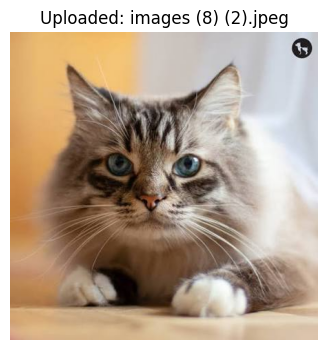


               LIVE TEST RESULTS               

1. STANDARD SOFTMAX (The Baseline):
   Prediction: persian+cat
   Confidence: 87.83%

2. MULTI-LAYER MAHALANOBIS (Your Method):
   Layer1 Distance:   9.02 (Limit: 64)final
   Layer2 Distance:  11.34 (Limit: 128)final
   Layer3 Distance:  32.43 (Limit: 256)final
   Layer4 Distance: 531.35 (Limit: 512)final

   -> TOTAL AGGREGATED DISTANCE: 584.15


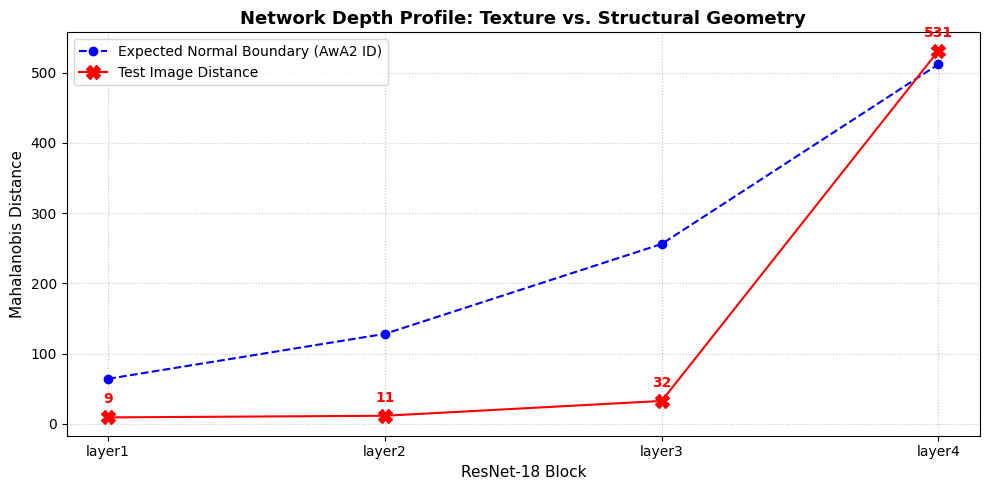

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
import io
from google.colab import files

print("="*60)
print(" MULTI-LAYER LIVE OOD TESTER (Texture vs Geometry)")
print("="*60)

# 1. Upload the image
uploaded = files.upload()

if not uploaded:
    print("No image uploaded. Please run the cell again.")
else:
    filename = next(iter(uploaded))
    img = Image.open(io.BytesIO(uploaded[filename])).convert('RGB')

    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Uploaded: {filename}")
    plt.show()

    # Apply your standard transforms
    img_tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        # 2. Forward pass
        logits, _ = model(img_tensor)

        # --- SOFTMAX BASELINE ---
        probs = F.softmax(logits, dim=1)
        max_prob, predicted_class_idx = torch.max(probs, dim=1)

        if 'awa2_data' in globals():
            predicted_class_name = awa2_data.classes[predicted_class_idx.item()]
        else:
            predicted_class_name = f"Class {predicted_class_idx.item()}"

        # --- MULTI-LAYER MAHALANOBIS ---
        layers = ['layer1', 'layer2', 'layer3', 'layer4']
        image_distances = []
        total_aggregated_distance = 0

        for layer in layers:
            test_feat = intermediate_features[layer][0].unsqueeze(0).cpu()

            layer_dists = []
            for c in range(num_classes):
                delta = test_feat - layer_class_means[layer][c]
                left = torch.matmul(delta, layer_inverse_covariances[layer])
                dist = torch.sum(left * delta, dim=1).item()
                layer_dists.append(dist)

            min_dist_for_layer = min(layer_dists)
            image_distances.append(min_dist_for_layer)
            total_aggregated_distance += min_dist_for_layer

    # --- CORRECTED DECISION LOGIC ---
    # We use the feature dimension size of each layer as its expected baseline limit
    expected_dists = [layer_inverse_covariances[l].shape[0] for l in layers]

    # An image is OOD if it exceeds the expected limit at ANY depth
    is_ood = any(dist > exp for dist, exp in zip(image_distances, expected_dists))

    # 3. Print the text results
    print("\n" + "="*50)
    print("               LIVE TEST RESULTS               ")
    print("="*50)

    print(f"\n1. STANDARD SOFTMAX (The Baseline):")
    print(f"   Prediction: {predicted_class_name}")
    print(f"   Confidence: {max_prob.item() * 100:.2f}%\n")

    print(f"2. MULTI-LAYER MAHALANOBIS (Your Method):")
    for i, layer in enumerate(layers):
        status = "final"
        # status = " <-- [ANOMALY DETECTED]" if image_distances[i] > expected_dists[i] else ""
        print(f"   {layer.capitalize()} Distance: {image_distances[i]:>6.2f} (Limit: {expected_dists[i]}){status}")

    print(f"\n   -> TOTAL AGGREGATED DISTANCE: {total_aggregated_distance:.2f}")

    # if is_ood:
    #     print(f"\n   -> CONCLUSION: REJECTED! (Out-of-Distribution structural anomaly)")
    # else:
    #     print(f"\n   -> CONCLUSION: ACCEPTED. (Safely inside In-Distribution bounds)")

    # 4. Plot the Layer-by-Layer visual profile
    plt.figure(figsize=(10, 5))

    plt.plot(layers, expected_dists, marker='o', linestyle='--', color='blue', label='Expected Normal Boundary (AwA2 ID)')
    plt.plot(layers, image_distances, marker='X', markersize=10, linestyle='-', color='red', label='Test Image Distance')

    plt.title('Network Depth Profile: Texture vs. Structural Geometry', fontsize=13, fontweight='bold')
    plt.xlabel('ResNet-18 Block', fontsize=11)
    plt.ylabel('Mahalanobis Distance', fontsize=11)
    plt.legend(loc="upper left")
    plt.grid(True, linestyle=':', alpha=0.7)

    # Annotate the exact numbers on the graph
    for i, dist in enumerate(image_distances):
        plt.annotate(f"{dist:.0f}", (layers[i], image_distances[i]),
                     textcoords="offset points", xytext=(0,10), ha='center', color='red', fontweight='bold')

    plt.tight_layout()
    plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Collect the data for the graph ---
# (Make sure this runs inside your Live Demo cell after features are extracted)

layers = ['layer1', 'layer2', 'layer3', 'layer4']
image_distances = []
avg_normal_distances = [] # We will calculate the mean distance for normal data

for layer in layers:
    # 1. Calculate the test image's distance for this specific layer
    test_feat = intermediate_features[layer][0].unsqueeze(0).cpu()

    layer_dists = []
    for c in range(num_classes):
        delta = test_feat - layer_class_means[layer][c]
        left = torch.matmul(delta, layer_inverse_covariances[layer])
        dist = torch.sum(left * delta, dim=1).item()
        layer_dists.append(dist)

    min_dist_for_layer = min(layer_dists)
    image_distances.append(min_dist_for_layer)

    # 2. Get the expected normal average distance for context
    # (Using the diagonal of the inverse covariance as a rough proxy for expected variance)
    expected_dist = layer_inverse_covariances[layer].shape[0]
    avg_normal_distances.append(expected_dist)

# --- 2. Plot the Graph ---
plt.figure(figsize=(10, 6))

# Plot the expected normal boundary
plt.plot(layers, avg_normal_distances, marker='o', linestyle='--', color='blue', label='Expected Normal Boundary (ID)')

# Plot the test image's actual distance
plt.plot(layers, image_distances, marker='X', markersize=10, linestyle='-', color='red', label='Test Image Distance')

# Styling the graph to look academic and professional
plt.title('Multi-Layer Mahalanobis Distance Profile', fontsize=14, fontweight='bold')
plt.xlabel('ResNet-18 Network Depth', fontsize=12)
plt.ylabel('Mahalanobis Distance', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)

# Add annotations to show the exact numbers
for i, dist in enumerate(image_distances):
    plt.annotate(f"{dist:.1f}", (layers[i], image_distances[i]),
                 textcoords="offset points", xytext=(0,10), ha='center', color='red', fontweight='bold')

plt.tight_layout()
plt.show()

 ULTIMATE LIVE OOD TESTER (TPR95 Thresholds)


Saving download (1).jpeg to download (1) (1).jpeg


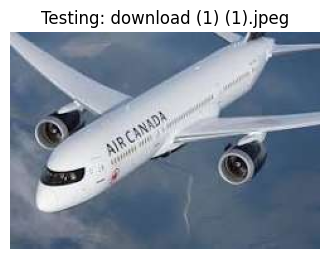


       LIVE TEST RESULTS       

1. STANDARD SOFTMAX (The Baseline):
   Prediction: dolphin
   Confidence: 50.16%

2. MAHALANOBIS FEATURE-SPACE (Your Method):
   Distance from Safety Bounds: 1342.46
   Strict TPR95 Boundary for Class 12: 698.40

   -> CONCLUSION: REJECTED! (Exceeds custom class boundary)


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
import io
from google.colab import files

print("="*50)
print(" ULTIMATE LIVE OOD TESTER (TPR95 Thresholds)")
print("="*50)

uploaded = files.upload()

if not uploaded:
    print("No image uploaded. Please run the cell again.")
else:
    filename = next(iter(uploaded))
    img = Image.open(io.BytesIO(uploaded[filename])).convert('RGB')

    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Testing: {filename}")
    plt.show()

    img_tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logits, features = model(img_tensor)

        # --- SOFTMAX ---
        probs = F.softmax(logits, dim=1)
        max_prob, predicted_class_idx = torch.max(probs, dim=1)

        if 'awa2_data' in globals():
            predicted_class_name = awa2_data.classes[predicted_class_idx.item()]
        else:
            predicted_class_name = f"Class {predicted_class_idx.item()}"

        # --- MAHALANOBIS ---
        md_distances = []
        for c in range(num_classes):
            delta = features - class_means[c]
            left = torch.matmul(delta, inverse_covariance)
            dist = torch.sum(left * delta, dim=1)
            md_distances.append(dist.item())

        min_md_distance = min(md_distances)
        closest_class_idx = md_distances.index(min_md_distance)

        # Get the strict 95th percentile boundary for THIS specific class
        specific_threshold = class_thresholds[closest_class_idx]

    print("\n" + "="*40)
    print("       LIVE TEST RESULTS       ")
    print("="*40)

    print(f"\n1. STANDARD SOFTMAX (The Baseline):")
    print(f"   Prediction: {predicted_class_name}")
    print(f"   Confidence: {max_prob.item() * 100:.2f}%")

    print(f"\n2. MAHALANOBIS FEATURE-SPACE (Your Method):")
    print(f"   Distance from Safety Bounds: {min_md_distance:.2f}")
    print(f"   Strict TPR95 Boundary for Class {closest_class_idx}: {specific_threshold:.2f}")

    if min_md_distance > specific_threshold:
        print(f"\n   -> CONCLUSION: REJECTED! (Exceeds custom class boundary)")
    else:
        print(f"\n   -> CONCLUSION: ACCEPTED. (Safely inside class bounds)")

 LIVE OOD TESTER: Upload any image to test!


Saving images (7).jpeg to images (7).jpeg


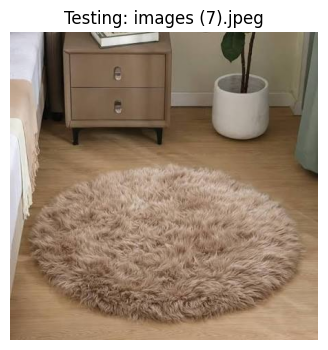


       LIVE TEST RESULTS       

1. STANDARD SOFTMAX (The Baseline):
   Prediction: german+shepherd
   Confidence: 14.91%

2. MAHALANOBIS FEATURE-SPACE (Your Method):
   Distance from Safety Bounds: 688.16
   Average Normal Animal Distance: 475.54

   -> CONCLUSION: REJECTED! (Out-of-Distribution)


In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
import io
from google.colab import files

print("="*50)
print(" LIVE OOD TESTER: Upload any image to test!")
print("="*50)

# 1. This opens the Colab upload button!
uploaded = files.upload()

if not uploaded:
    print("No image uploaded. Please run the cell again.")
else:
    # 2. Grab the file you just uploaded
    filename = next(iter(uploaded))
    img = Image.open(io.BytesIO(uploaded[filename])).convert('RGB')

    # Display it
    plt.figure(figsize=(4,4))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Testing: {filename}")
    plt.show()

    # 3. Transform and pass through the model
    img_tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logits, features = model(img_tensor)

        # --- SOFTMAX ---
        probs = F.softmax(logits, dim=1)
        max_prob, predicted_class_idx = torch.max(probs, dim=1)

        if 'awa2_data' in globals():
            predicted_class_name = awa2_data.classes[predicted_class_idx.item()]
        else:
            predicted_class_name = f"Class {predicted_class_idx.item()}"

        # --- MAHALANOBIS ---
        md_distances = []
        for c in range(num_classes):
            delta = features - class_means[c]
            left = torch.matmul(delta, inverse_covariance)
            dist = torch.sum(left * delta, dim=1)
            md_distances.append(dist.item())

        min_md_distance = min(md_distances)

    # 4. Print the final results
    print("\n" + "="*40)
    print("       LIVE TEST RESULTS       ")
    print("="*40)

    print(f"\n1. STANDARD SOFTMAX (The Baseline):")
    print(f"   Prediction: {predicted_class_name}")
    print(f"   Confidence: {max_prob.item() * 100:.2f}%")

    print(f"\n2. MAHALANOBIS FEATURE-SPACE (Your Method):")
    print(f"   Distance from Safety Bounds: {min_md_distance:.2f}")
    print(f"   Average Normal Animal Distance: {avg_id_distance:.2f}")

    # Threshold check
    if min_md_distance > (avg_id_distance * 1.3):
        print(f"\n   -> CONCLUSION: REJECTED! (Out-of-Distribution)")
    else:
        print(f"\n   -> CONCLUSION: ACCEPTED. (In-Distribution)")